# 03 · KDE verification of my cell-type labels

**What this notebook claims, and what it does not.** It is a cell-level **consistency diagnostic**: it measures how well each cell fits the
distribution of its assigned type in a chosen PCA space, and prioritizes cells for review. It is not an independent validator of cell identity,
and a flag is not a verified error.

Notebooks 01 and 02 named **clusters**. Every cell in a cluster inherits the name, including doublets,
badly segmented cells and cells in transitional states. This notebook checks the label of **each cell**.

**Idea.** Each cell type $c$ becomes a smooth density $p(x \mid c)$ in PCA space, estimated with a Gaussian
kernel density estimate (KDE). A cell $x$ with my label $c$ is then:

| verdict | rule |
|---|---|
| **fits another type** | another type $c'$ explains it much better, $\dfrac{p(c' \mid x)}{p(c \mid x)} \ge$ `ODDS`, **and** the cell is typical for $c'$ (above $c'$'s outlier threshold) |
| **outlier** | its own type barely explains it: $\log p(x \mid c)$ below the `Q`-th percentile of typical type-$c$ cells |
| **confirmed** | neither |

The posterior is $p(c \mid x) = \pi_c\, p(x \mid c) \,/\, \sum_{c'} \pi_{c'}\, p(x \mid c')$, with priors $\pi_c$ equal to the type frequencies.
All computations are in log space (`scipy.special.logsumexp`). When both rules apply, "fits another type" wins, because it says more.

**Steps**

1. Set up the method: whitened KDE, bandwidth choice, cross-fitting.
2. Work through a 2-D toy example to see what the check does.
3. Run the check on Xenium: flag rates, tissue map, flagged-cell profiles.
4. Run the check on CODEX: the same outputs.
5. Test sensitivity to `K`, the bandwidth, `N` and `Q`.

The authors' labels are still not used.

## Parameters

In [1]:
from pathlib import Path

RESULTS_DIR = Path("results")
FIG_DIR = RESULTS_DIR / "figures"

K        = 10                       # PCs used for the KDE (first K of the clustering PCs)
N        = 1000                     # max cells per type used as KDE support
N_VAL    = 500                      # max held-out cells per type for bandwidth choice and outlier threshold
H_GRID   = [0.5, 0.75, 1.0, 1.5, 2.0]   # bandwidth = factor x Scott's rule
Q        = 1.0                      # outlier: below the Q-th percentile of typical own-type cells (%)
ODDS     = 10                       # fits another type: another type at least ODDS times more probable
TILE_UM  = 500                      # Xenium cross-fitting: spatial tile size (µm)
SENS_N   = 20000                    # maximum cells scored in each sensitivity run
SEED     = 0


In [2]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.linalg import solve_triangular
from scipy.special import logsumexp
from sklearn.neighbors import KernelDensity

FIG_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(SEED)


In [3]:
# record the software versions of this run (a fixed seed alone does not guarantee identical results across versions)
import sys
from importlib.metadata import version
print("python", sys.version.split()[0])
print({p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "scanpy", "anndata",
                                "squidpy", "igraph", "leidenalg", "matplotlib"]})

python 3.13.17
{'numpy': '2.4.6', 'pandas': '3.0.5', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'scanpy': '1.12.4', 'anndata': '0.13.4', 'squidpy': '1.8.3', 'igraph': '1.0.0', 'leidenalg': '0.12.0', 'matplotlib': '3.11.2'}


## 1 · The method

**Whitening.** The PCs have different spreads, and each cell type can be elongated in its own directions. For each type, support cells are centered and transformed using their own covariance estimate:

$$y = L_c^{-1}(x - \mu_c), \qquad \hat\Sigma_c = L_c L_c^\top.$$

A KDE with bandwidth $h$ on $y$ corresponds to a covariance-shaped kernel in the original PC space. Changing variables adds back the Jacobian, so the type-specific densities remain comparable:

$$\log p(x \mid c) = \log p_y(y \mid c) - \log\lvert\det L_c\rvert.$$

**Bandwidth.** After whitening, Scott's rule gives $h_0 = n^{-1/(K+4)}$. The final $h$ is $h_0$ times the factor in `H_GRID` with the highest mean log-likelihood on held-out cells of the same type.

**Support and validation.** At most `N` cells per type form the KDE support. A separate subset is held out for bandwidth selection and the outlier threshold. The whitening mean and covariance are now estimated from support cells only, avoiding leakage of validation cells into the fitted transform.

**Outlier threshold.** The `Q`-th percentile of held-out type-$c$ log likelihood is used as the outlier threshold. This is an empirical calibration threshold, not a guarantee that exactly `Q`% of cells in the opposite cross-fitting fold will be flagged.

**Cross-fitting.** A cell that helps build its own type's density can look artificially typical. Cells are split into two halves: by 500 µm tissue tiles for Xenium, and by patient for CODEX. The densities are fitted on one half and score the other, then the halves swap. This also reduces leakage from spatially adjacent cells or regions from the same patient.

**Interpretation.** KDE flags are expression-space consistency checks, not definitive proof of a wrong annotation.

**Built-in circularity.** The labels come from Leiden clusters of a kNN graph built in the same PC space. Most cells are therefore consistent with their own type almost by construction. The check is informative mainly at cluster boundaries and for small types, and it cannot detect an error shared by a whole cluster, such as a wrong name. Cross-fitting removes self-scoring, not this circularity.

**Cross-fitting covers the KDE step only.** The PCA coordinates and the cluster labels were computed on the full dataset, so held-out cells did influence the representation and the clusters their labels come from. The check asks whether a cell fits an already-established label; it is not an end-to-end validation of the annotation pipeline. That would require fitting PCA and clustering on training data and assigning held-out data by a fixed rule, which is out of scope here. Spatial tiles also do not make folds fully independent: cells near a tile edge have close neighbours in the other fold (tested in section 5b).

**Model-based probabilities.** The posterior uses priors equal to the label frequencies in the fitting fold. It is a model quantity, not a calibrated biological probability; the 1% and 10:1 thresholds are operational definitions, not calibrated error rates. Results depend on the selected PCs, cell-type sample sizes, marker representation in PCA space, and the KDE assumptions.


In [4]:
def fit_type_kdes(X, labels, types, n_support=N, h_grid=H_GRID, seed=SEED):
    """Fit one whitened Gaussian KDE per type.

    The whitening transform is estimated from KDE support cells only. Validation
    cells are not used to estimate the transform, select support, or fit the KDE.
    """
    X = np.asarray(X, dtype=float)
    labels = np.asarray(labels).astype(str)
    if X.ndim != 2:
        raise ValueError(f"X must be a 2-D cells-by-features array; got shape {X.shape}.")
    if len(labels) != X.shape[0]:
        raise ValueError("labels and X have different numbers of cells.")
    if not np.isfinite(X).all():
        raise ValueError("X contains NaN or infinite values; clean the PCA coordinates before KDE fitting.")
    if not h_grid or any((not np.isfinite(h) or h <= 0) for h in h_grid):
        raise ValueError("Every bandwidth factor in h_grid must be finite and positive.")

    rng = np.random.default_rng(seed)
    d = X.shape[1]
    models = {}
    for c in types:
        Xc = X[labels == c]
        # Covariance needs more support observations than dimensions. Keep a
        # separate validation set for bandwidth selection and thresholding.
        n_val = min(N_VAL, max(5, len(Xc) // 5))
        if len(Xc) < n_val + d + 2:
            raise ValueError(
                f"Cell type {c!r} has only {len(Xc)} cells in this fitting fold; "
                f"need at least {n_val + d + 2} to estimate a {d}-D covariance "
                "and retain at least five validation cells. Consider fewer PCs or "
                "a documented rare-type strategy."
            )

        idx = rng.permutation(len(Xc))
        val = Xc[idx[:n_val]]
        sup = Xc[idx[n_val:n_val + min(n_support, len(Xc) - n_val)]]
        if len(sup) <= d:
            raise ValueError(f"Insufficient KDE support for type {c!r}: {len(sup)} cells for {d} dimensions.")

        # Estimate the transform using support cells only (no validation leakage).
        mu = sup.mean(axis=0)
        cov = np.cov(sup, rowvar=False)
        cov = np.atleast_2d(cov)
        # Small scale-aware diagonal regularization protects near-singular PC covariance.
        ridge = max(float(np.trace(cov) / d) * 1e-6, 1e-8)
        try:
            L = np.linalg.cholesky(cov + ridge * np.eye(d))
        except np.linalg.LinAlgError as exc:
            raise ValueError(f"Could not regularize covariance for cell type {c!r}.") from exc
        log_det_L = np.log(np.diag(L)).sum()

        def whiten(Z):
            return solve_triangular(L, (Z - mu).T, lower=True).T

        Ys, Yv = whiten(sup), whiten(val)
        h0 = len(Ys) ** (-1 / (d + 4))  # Scott's rule in whitened space
        heldout = {
            f: KernelDensity(bandwidth=f * h0).fit(Ys).score_samples(Yv).mean()
            for f in h_grid
        }
        f_best = max(heldout, key=heldout.get)
        kde = KernelDensity(bandwidth=f_best * h0).fit(Ys)
        val_logp = kde.score_samples(Yv) - log_det_L
        models[c] = dict(
            mu=mu, L=L, log_det_L=log_det_L, kde=kde, h0=h0, factor=f_best,
            n_support=len(Ys), val_logp=val_logp, prior=float((labels == c).mean())
        )

    total = sum(m["prior"] for m in models.values())
    if not np.isfinite(total) or total <= 0:
        raise ValueError("Could not calculate positive class priors for the requested cell types.")
    for m in models.values():
        m["prior"] /= total
    return models


def log_lik(X, models):
    """Return log p(x | c) for each cell and checked type."""
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or not np.isfinite(X).all():
        raise ValueError("Scoring matrix must be 2-D and contain only finite values.")
    out = {}
    for c, m in models.items():
        Y = solve_triangular(m["L"], (X - m["mu"]).T, lower=True).T
        out[c] = m["kde"].score_samples(Y) - m["log_det_L"]
    return pd.DataFrame(out)


def verdicts(LL, labels, models, q=Q, odds=ODDS, uniform_prior=False):
    """Assign per-cell verdicts using posterior odds and held-out outlier thresholds."""
    types = list(LL.columns)
    labels = np.asarray(labels).astype(str)
    if len(labels) != len(LL):
        raise ValueError("Scored labels and likelihood rows have different lengths.")
    missing = sorted(set(labels) - set(types))
    if missing:
        raise ValueError(f"Cannot score labels without fitted KDEs: {missing}")
    if not 0 <= q <= 100:
        raise ValueError("q must be between 0 and 100.")
    if not np.isfinite(odds) or odds <= 1:
        raise ValueError("odds must be finite and greater than 1.")

    log_prior = np.zeros(len(types)) if uniform_prior else np.log([models[c]["prior"] for c in types])
    log_post = LL.to_numpy() + log_prior
    log_post -= logsumexp(log_post, axis=1, keepdims=True)

    type_idx = {c: i for i, c in enumerate(types)}
    own = np.array([type_idx[l] for l in labels])
    rows = np.arange(len(labels))
    lp_own = log_post[rows, own]
    other = log_post.copy()
    other[rows, own] = -np.inf
    best_other = other.argmax(axis=1)
    log_odds = other[rows, best_other] - lp_own

    thr = np.array([np.percentile(models[c]["val_logp"], q) for c in types])
    ll_own = LL.to_numpy()[rows, own]
    outlier = ll_own < thr[own]
    ll_other = LL.to_numpy()[rows, best_other]
    mislabeled = (log_odds >= np.log(odds)) & (ll_other >= thr[best_other])
    flag = np.where(mislabeled, "fits another type", np.where(outlier, "outlier", "confirmed"))
    return pd.DataFrame({
        "logp_own": ll_own,
        "post_own": np.exp(lp_own),
        "best_other": np.array(types)[best_other],
        "post_best_other": np.exp(other[rows, best_other]),
        "log10_odds": log_odds / np.log(10),
        "flag": flag,
    })


def cross_fit(X, labels, fold, types):
    """Fit on one fold and score the other, then swap."""
    X = np.asarray(X, dtype=float)
    labels = np.asarray(labels).astype(str)
    fold = np.asarray(fold)
    if X.ndim != 2 or len(labels) != X.shape[0] or len(fold) != X.shape[0]:
        raise ValueError("X, labels, and fold must have the same number of cells.")
    if not np.isfinite(X).all():
        raise ValueError("PCA coordinates contain NaN or infinite values.")
    if set(np.unique(fold)) != {0, 1}:
        raise ValueError(f"Expected exactly two folds encoded 0 and 1; found {np.unique(fold).tolist()}.")
    types = list(types)
    if not types:
        raise ValueError("No cell types are available for KDE verification.")

    res, bw = [], []
    for f in (0, 1):
        fit = fold == f
        score = (fold != f) & np.isin(labels, types)
        fit_labels = labels[fit]
        missing = [c for c in types if not np.any(fit_labels == c)]
        if missing:
            raise ValueError(f"Fold {f} has no fitting cells for these types: {missing}")
        models = fit_type_kdes(X[fit], fit_labels, types, seed=SEED + f)
        r = verdicts(log_lik(X[score], models), labels[score], models)
        r.index = np.flatnonzero(score)
        res.append(r)
        bw += [
            {"fold": f, "type": c, "support": m["n_support"],
             "h0 (Scott)": m["h0"], "factor": m["factor"], "h": m["h0"] * m["factor"]}
            for c, m in models.items()
        ]
    return pd.concat(res).sort_index(), pd.DataFrame(bw)


## 2 · Toy example: what the check does

There are two classes in 2-D. Class A is elongated and class B is round. Below:

- **Top row:** the class-A density at three bandwidths. A very small $h$ gives a spiky density that memorizes the points, a very large $h$ blurs the shape, and the held-out choice sits in between.
- **Bottom left:** the decision boundary. Where A and B are equally probable, and the lines where one is `ODDS` times more probable than the other.
- **Bottom right:** the outlier region. Points below the `Q`-th percentile of both classes' typical densities.

Three test points labeled "A" show the three verdicts. The far-away point shows why "fits another type" also requires the
competitor to find the cell typical. Far from all data, the ratio of two densities is decided by whose tail decays more slowly, which says nothing about the cell.

In [5]:
trng = np.random.default_rng(1)
A = trng.multivariate_normal([0, 0], [[4, 1.8], [1.8, 1]], 600)
B = trng.multivariate_normal([4, -2.5], [[0.6, 0], [0, 0.6]], 400)
Xt = np.vstack([A, B]); yt = np.array(["A"] * len(A) + ["B"] * len(B))
toy = fit_type_kdes(Xt, yt, ["A", "B"], n_support=500)
print({c: f"h = {m['factor']} x Scott" for c, m in toy.items()})

tests = np.array([[0.5, 0.3], [4.1, -2.6], [-1.0, 4.5]])           # all labeled "A"
tv = verdicts(log_lik(tests, toy), np.array(["A"] * 3), toy)
tv.insert(0, "point", ["typical A", "inside B", "far from both"])
tv.round(3)

{'A': 'h = 1.0 x Scott', 'B': 'h = 1.0 x Scott'}


,point,logp_own,post_own,best_other,post_best_other,log10_odds,flag
0,typical A,-1.772,1.0,B,0.0,-11.488,confirmed
1,inside B,-222.146,0.0,B,1.0,95.693,fits another type
2,far from both,-279.071,0.0,B,1.0,25.463,outlier


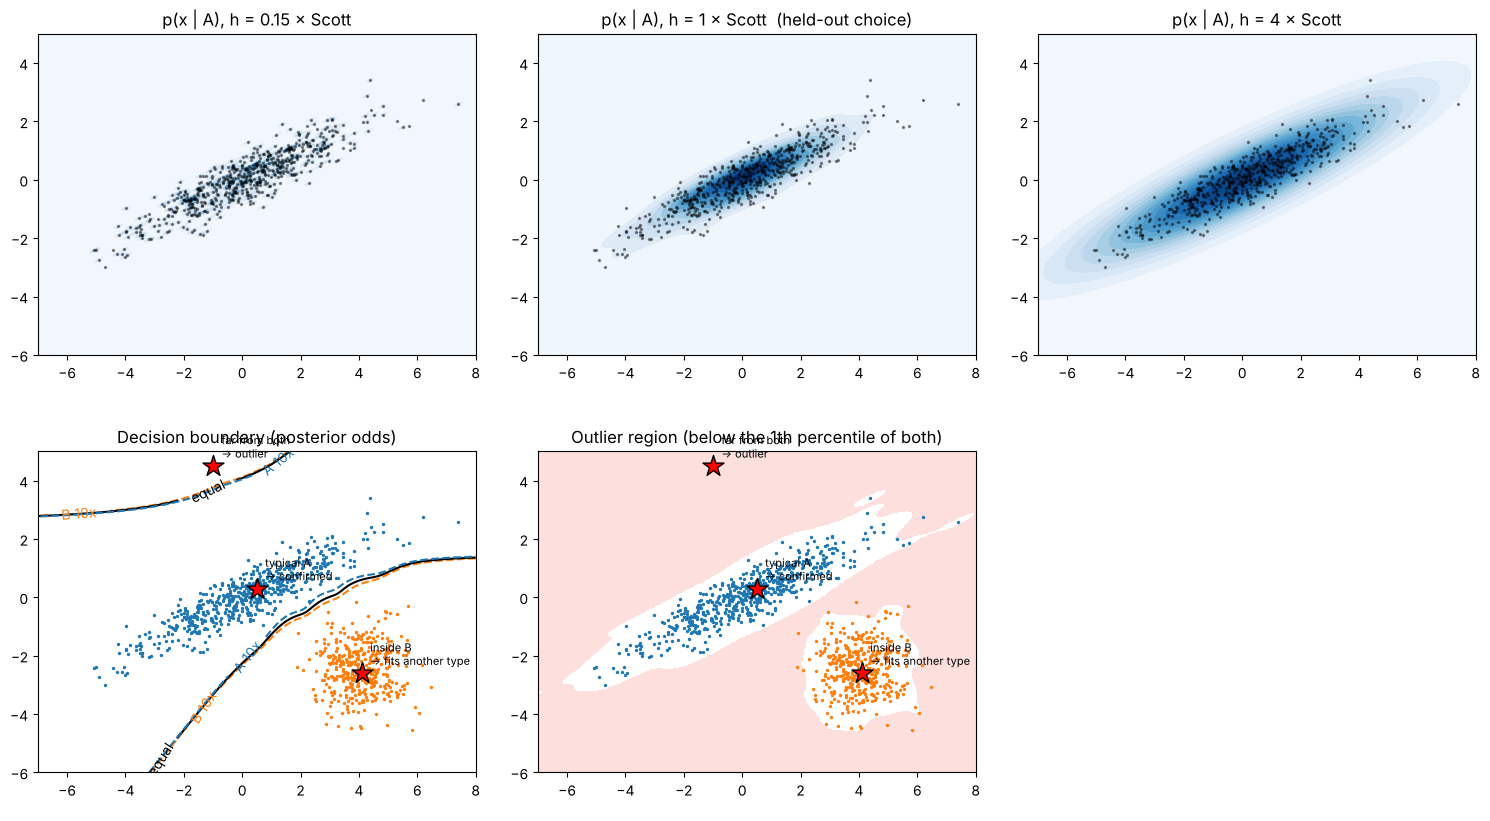

In [6]:
g = np.linspace(-7, 8, 300); gx, gy = np.meshgrid(g, np.linspace(-6, 5, 250))
grid = np.c_[gx.ravel(), gy.ravel()]

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
mA = toy["A"]
for ax, f in zip(axes[0], [0.15, mA["factor"], 4.0]):
    one = fit_type_kdes(Xt[yt == "A"], yt[yt == "A"], ["A"], n_support=500, h_grid=[f])
    dens = np.exp(log_lik(grid, one)["A"].to_numpy()).reshape(gx.shape)
    ax.contourf(gx, gy, dens, levels=15, cmap="Blues")
    ax.scatter(*A.T, s=2, c="k", alpha=0.4)
    ax.set_title(f"p(x | A), h = {f:g} × Scott" + ("  (held-out choice)" if f == mA["factor"] else ""))

LLg = log_lik(grid, toy)
lo = (LLg["A"] + np.log(toy["A"]["prior"]) - LLg["B"] - np.log(toy["B"]["prior"])).to_numpy().reshape(gx.shape) / np.log(10)
ax = axes[1, 0]
ax.scatter(*A.T, s=2, c="tab:blue"); ax.scatter(*B.T, s=2, c="tab:orange")
cs = ax.contour(gx, gy, lo, levels=[-np.log10(ODDS), 0, np.log10(ODDS)], colors=["tab:orange", "k", "tab:blue"],
                linestyles=["--", "-", "--"])
ax.clabel(cs, fmt={-np.log10(ODDS): f"B {ODDS}x", 0: "equal", np.log10(ODDS): f"A {ODDS}x"})
ax.set_title("Decision boundary (posterior odds)")

ax = axes[1, 1]
thrA = np.percentile(toy["A"]["val_logp"], Q); thrB = np.percentile(toy["B"]["val_logp"], Q)
out_region = ((LLg["A"] < thrA) & (LLg["B"] < thrB)).to_numpy().reshape(gx.shape)
ax.contourf(gx, gy, out_region, levels=[0.5, 1], colors=["#fde0dd"])
ax.scatter(*A.T, s=2, c="tab:blue"); ax.scatter(*B.T, s=2, c="tab:orange")
ax.set_title(f"Outlier region (below the {Q:g}th percentile of both)")

for ax in axes[1, :2]:
    for (px, py), name, v in zip(tests, tv["point"], tv["flag"]):
        ax.scatter(px, py, marker="*", s=250, c="red", edgecolor="k", zorder=5)
        ax.annotate(f"{name}\n→ {v}", (px, py), xytext=(6, 6), textcoords="offset points", fontsize=8)
axes[1, 2].axis("off")
for ax in axes.flat[:5]:
    ax.set(xlim=(-7, 8), ylim=(-6, 5)); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

### Helpers for the real data

These short functions are used for both datasets: the flag-rate plot, the tissue flag map, and a heatmap comparing flagged cells with confirmed ones.

In [7]:
FLAG_COLORS = {"confirmed": "#d9d9d9", "outlier": "#4c72b0", "fits another type": "#d62728"}

def flag_table(res, labels):
    # res indices are positional cell indices from the AnnData object.
    lab = np.asarray(labels).astype(str)[res.index.to_numpy()]
    t = pd.crosstab(
        pd.Index(lab, name=None), res["flag"].to_numpy(),
        normalize="index"
    ).rename_axis(index=None, columns=None).reindex(columns=list(FLAG_COLORS), fill_value=0) * 100
    t.insert(0, "n_cells", pd.Series(lab).value_counts().reindex(t.index, fill_value=0))
    mis = res["flag"].to_numpy() == "fits another type"
    comp = pd.Series(res["best_other"].to_numpy()[mis], index=lab[mis]).groupby(level=0).agg(
        lambda s: s.value_counts().index[0]
    )
    t["main competitor"] = comp.reindex(t.index).fillna("")
    return t.sort_values("confirmed")


def plot_flag_rates(t, title):
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(t) + 1))
    left = np.zeros(len(t))
    for f, col in FLAG_COLORS.items():
        ax.barh(t.index, t[f], left=left, color=col, label=f)
        left += t[f].to_numpy()
    ax.set(xlabel="% of cells", title=title, xlim=(0, 100))
    ax.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    return fig


def plot_flag_map(ax, xy, flag, title, s=0.3):
    for f in ["confirmed", "outlier", "fits another type"]:
        m = flag == f
        ax.scatter(xy[m, 0], xy[m, 1], s=s if f == "confirmed" else 3 * s,
                   c=FLAG_COLORS[f], rasterized=True, linewidths=0, label=f)
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.set(title=title, xticks=[], yticks=[])


def profile_heatmap(ax, X, var_names, labels, res, c, c_star, n_markers=4):
    """Plot group-average z-scores without densifying the full expression matrix."""
    labels = np.asarray(labels).astype(str)
    n_cells = len(labels)
    if X.shape[0] != n_cells:
        raise ValueError("Expression matrix and labels have different numbers of cells.")

    # Mean and variance by marker; works with both sparse and dense matrices.
    if sparse.issparse(X):
        Xs = X.tocsr()
        mean = np.asarray(Xs.mean(axis=0)).ravel()
        mean_sq = np.asarray(Xs.multiply(Xs).mean(axis=0)).ravel()
        def row_mean(mask):
            if not mask.any():
                return np.full(X.shape[1], np.nan)
            return np.asarray(Xs[mask].mean(axis=0)).ravel()
    else:
        Xd = np.asarray(X, dtype=float)
        mean = Xd.mean(axis=0)
        mean_sq = np.square(Xd).mean(axis=0)
        def row_mean(mask):
            return Xd[mask].mean(axis=0) if mask.any() else np.full(Xd.shape[1], np.nan)

    std = np.sqrt(np.maximum(mean_sq - mean ** 2, 0))
    std = std + 1e-9

    flag = pd.Series("", index=np.arange(n_cells), dtype=object)
    best_other = pd.Series("", index=np.arange(n_cells), dtype=object)
    flag.loc[res.index] = res["flag"].to_numpy()
    best_other.loc[res.index] = res["best_other"].to_numpy()

    masks = {
        f"{c} (confirmed)": (labels == c) & (flag.to_numpy() == "confirmed"),
        f"{c} → flagged as {c_star}": (labels == c) & (flag.to_numpy() == "fits another type") & (best_other.to_numpy() == c_star),
        f"{c_star} (confirmed)": (labels == c_star) & (flag.to_numpy() == "confirmed"),
    }
    if not masks[next(iter(masks))].any() or not masks[list(masks)[-1]].any():
        ax.text(0.5, 0.5, "Insufficient confirmed cells for this pair", ha="center", va="center")
        ax.set_axis_off()
        return None

    means = pd.DataFrame({
        group: (row_mean(mask) - mean) / std for group, mask in masks.items()
    }, index=var_names)
    top_c = means.iloc[:, 0].sub(means.iloc[:, 2]).nlargest(n_markers).index
    top_s = means.iloc[:, 2].sub(means.iloc[:, 0]).nlargest(n_markers).index
    show = means.loc[list(dict.fromkeys(list(top_c) + list(top_s)))].T
    im = ax.imshow(show.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
    ax.set_xticks(range(show.shape[1]), show.columns, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(3), [f"{k} (n={masks[k].sum():,})" for k in show.index], fontsize=8)
    return im


def top_pairs(res, labels, n=3, min_cells=30):
    # Most frequent label -> competitor pairs among fits another type cells.
    mis = res[res["flag"] == "fits another type"]
    if mis.empty:
        return pd.DataFrame(columns=["label", "competitor", "n"])
    labels = np.asarray(labels).astype(str)
    pairs = pd.DataFrame({"label": labels[mis.index.to_numpy()], "competitor": mis["best_other"].to_numpy()})
    counts = pairs.value_counts().rename("n").reset_index()
    return counts[counts["n"] >= min_cells].head(n)


## 3 · Xenium breast cancer

**Cross-fitting folds.** The section is divided into 500 µm tiles, and whole tiles are randomly assigned to fold 0 or fold 1. Cells labeled `unknown` are not checked because there is no cell-type label to verify. The fold assignment is reproducible under `SEED`, but a different seed may alter the results.


176 tiles; fold sizes: [84687 79313]; checked types: 21


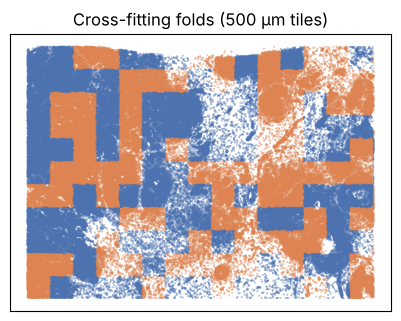

In [8]:
xe = sc.read_h5ad(RESULTS_DIR / "xenium_annotated.h5ad")
required_obsm = {"X_pca", "spatial"}
missing_obsm = required_obsm - set(xe.obsm.keys())
if missing_obsm:
    raise KeyError(f"Xenium AnnData is missing required obsm entries: {sorted(missing_obsm)}")
if "cell_type" not in xe.obs:
    raise KeyError("Xenium AnnData is missing obs['cell_type']. Run notebook 01 first.")
if xe.obsm["X_pca"].shape[1] < K:
    raise ValueError(f"Xenium has only {xe.obsm['X_pca'].shape[1]} PCs; K={K} was requested.")
if not xe.obs_names.is_unique:
    raise ValueError("Xenium cell IDs (obs_names) are not unique.")

X_xe = np.asarray(xe.obsm["X_pca"][:, :K], dtype=float)
lab_xe = xe.obs["cell_type"].astype(str).to_numpy()
types_xe = [c for c in pd.unique(lab_xe) if c != "unknown"]
if not types_xe:
    raise ValueError("No labeled Xenium cell types found; all cells may be 'unknown'.")

# Assign whole 500 µm tiles to folds so nearby cells cannot validate one another.
xy = np.asarray(xe.obsm["spatial"], dtype=float)
if xy.shape != (xe.n_obs, 2) or not np.isfinite(xy).all():
    raise ValueError("Xenium spatial coordinates must be a finite n_cells × 2 array.")
tile = (xy[:, 0] // TILE_UM).astype(int) * 1000 + (xy[:, 1] // TILE_UM).astype(int)
tiles = np.unique(tile)
if len(tiles) < 2:
    raise ValueError("Xenium needs at least two spatial tiles for cross-fitting.")
fold_of_tile = dict(zip(tiles, rng.permutation(np.arange(len(tiles)) % 2)))
fold_xe = np.array([fold_of_tile[t] for t in tile])
print(f"{len(tiles)} tiles; fold sizes: {np.bincount(fold_xe)}; checked types: {len(types_xe)}")

fig, ax = plt.subplots(figsize=(5, 3.6))
ax.scatter(xy[:, 0], xy[:, 1], s=0.05, c=np.where(fold_xe == 0, "#4c72b0", "#dd8452"), rasterized=True)
ax.set_aspect("equal"); ax.invert_yaxis(); ax.set(title="Cross-fitting folds (500 µm tiles)", xticks=[], yticks=[])
plt.show()


In [9]:
res_xe, bw_xe = cross_fit(X_xe, lab_xe, fold_xe, types_xe)
print("bandwidth factor chosen (x Scott), count of type-fold fits:")
print(bw_xe["factor"].value_counts().sort_index().to_string())
bw_xe.pivot(index="type", columns="fold", values="h").round(3).head()

bandwidth factor chosen (x Scott), count of type-fold fits:
factor
1.0    42


fold,0,1
type,,
Adipocytes,0.657,0.652
B cells,0.611,0.611
CAF / myofibroblasts,0.611,0.611
CD4+ T cells,0.611,0.611
CD8+ T cells,0.611,0.611


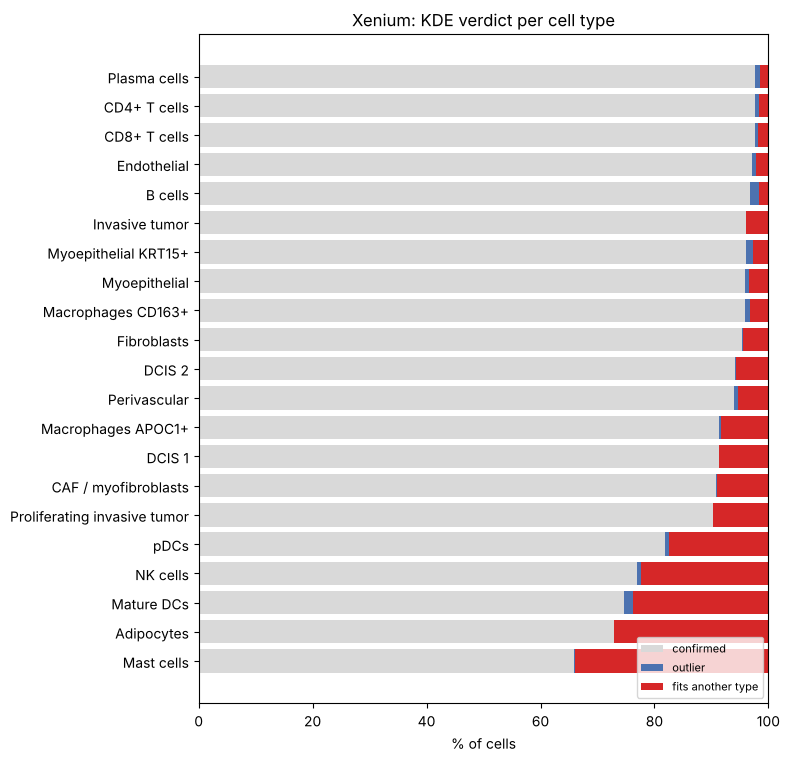

,n_cells,confirmed,outlier,fits another type,main competitor
Mast cells,760,65.9,0.1,33.9,Fibroblasts
Adipocytes,947,72.9,0.0,27.1,Fibroblasts
Mature DCs,716,74.7,1.5,23.7,CD4+ T cells
NK cells,832,76.9,0.7,22.4,CD8+ T cells
pDCs,620,81.9,0.6,17.4,Macrophages CD163+
Proliferating invasive tumor,7962,90.3,0.0,9.7,Invasive tumor
CAF / myofibroblasts,8524,90.8,0.2,9.0,Fibroblasts
DCIS 1,12278,91.3,0.0,8.7,DCIS 2
Macrophages APOC1+,5152,91.3,0.4,8.3,Macrophages CD163+
Perivascular,3690,94.0,0.6,5.4,CAF / myofibroblasts


In [10]:
t_xe = flag_table(res_xe, lab_xe)
plot_flag_rates(t_xe, "Xenium: KDE verdict per cell type").savefig(FIG_DIR / "xenium_kde_flag_rates.png", dpi=120)
plt.show()
t_xe.round(1)

In [11]:
overall = res_xe["flag"].value_counts(normalize=True).reindex(list(FLAG_COLORS)) * 100
print("all checked cells:", ", ".join(f"{k} {v:.1f}%" for k, v in overall.items()))

all checked cells: confirmed 94.6%, outlier 0.4%, fits another type 5.0%


### Where the flagged cells are

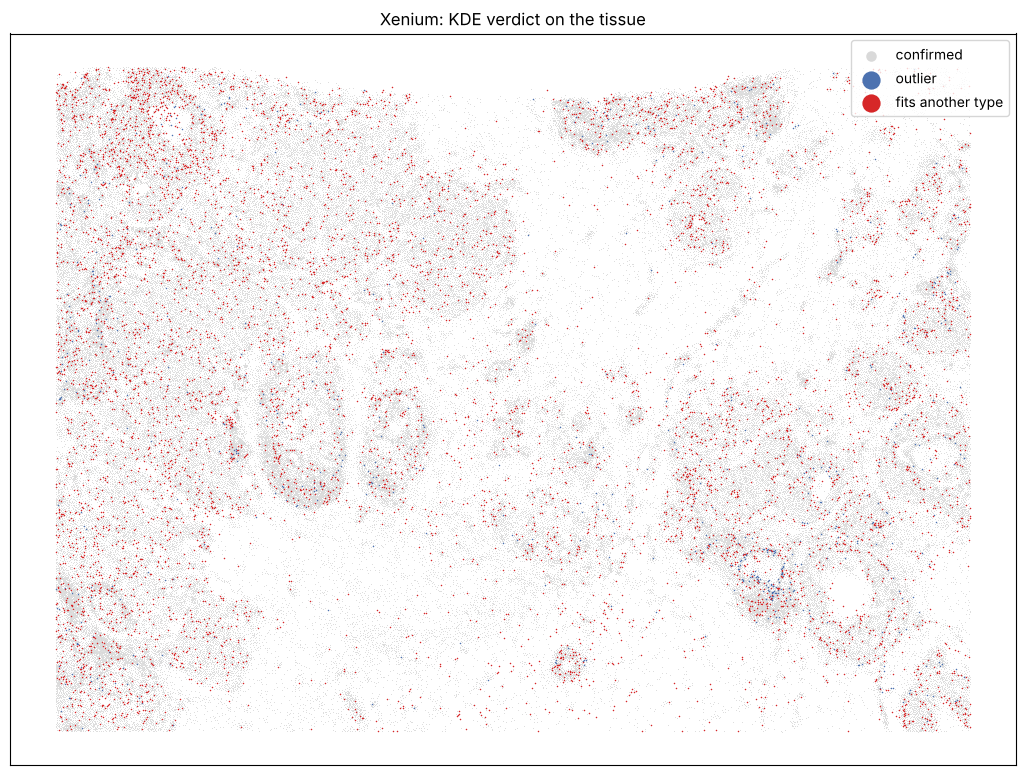

In [12]:
flag_full = np.full(xe.n_obs, "not checked", dtype=object)
flag_full[res_xe.index] = res_xe["flag"].to_numpy()

fig, ax = plt.subplots(figsize=(13, 9.5))
plot_flag_map(ax, xy, flag_full, "Xenium: KDE verdict on the tissue", s=0.4)
ax.legend(markerscale=12, loc="upper right", fontsize=10)
plt.savefig(FIG_DIR / "xenium_kde_flag_map.png", dpi=120); plt.show()

### What flagged cells look like

For the most frequent "my label → competing type" pairs, the heatmap compares three groups on the markers that separate
the two types: cells of my type that are confirmed, cells of my type that the KDE flags, and confirmed cells of the competing type.
If the flagged cells sit between the two, they are mixtures (doublets or spillover from a neighbor). If they look like the competitor, the label is likely wrong.

,label,competitor,n
0,Proliferating invasive tumor,Invasive tumor,498
1,DCIS 2,DCIS 1,398
2,DCIS 1,DCIS 2,352
3,Macrophages APOC1+,Macrophages CD163+,428


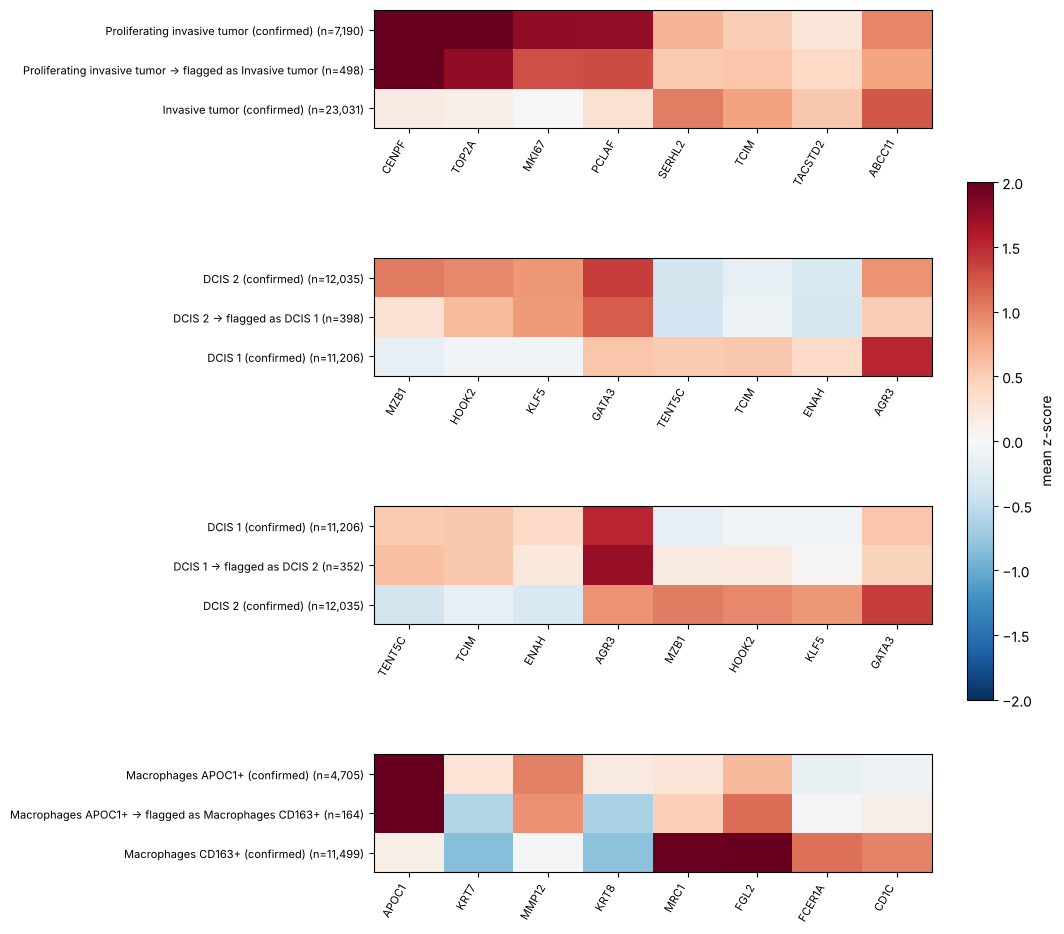

In [13]:
pairs_xe = top_pairs(res_xe, lab_xe)
apoc = "Macrophages APOC1+"  # case noted in notebook 01
if apoc in lab_xe and apoc not in pairs_xe["label"].values:
    mis = res_xe[(res_xe["flag"] == "fits another type") & (lab_xe[res_xe.index] == apoc)]
    if len(mis):
        pairs_xe.loc[len(pairs_xe)] = [apoc, mis["best_other"].value_counts().index[0], len(mis)]
display(pairs_xe)

if len(pairs_xe):
    fig, axes = plt.subplots(len(pairs_xe), 1, figsize=(9, 2.8 * len(pairs_xe)))
    fig.subplots_adjust(hspace=1.1)
    last_im = None
    for ax, (_, pair) in zip(np.atleast_1d(axes), pairs_xe.iterrows()):
        last_im = profile_heatmap(ax, xe.X, xe.var_names, lab_xe, res_xe,
                                  pair["label"], pair["competitor"])
    if last_im is not None:
        plt.colorbar(last_im, ax=np.atleast_1d(axes).tolist(), shrink=0.6, label="mean z-score")
    plt.savefig(FIG_DIR / "xenium_kde_flagged_profiles.png", dpi=120, bbox_inches="tight")
    plt.show()
else:
    print("No label→competitor pairs met the minimum cell-count threshold; profile heatmap skipped.")


In [14]:
out = res_xe.copy()
out.insert(0, "cell_id", xe.obs_names[res_xe.index]); out.insert(1, "cell_type", lab_xe[res_xe.index])
out.insert(2, "fold", fold_xe[res_xe.index])
out.to_csv(RESULTS_DIR / "xenium_kde.csv", index=False)
print(f"saved {len(out):,} cells to results/xenium_kde.csv")

saved 159,830 cells to results/xenium_kde.csv


## 4 · CODEX colorectal cancer

**Cross-fitting folds.** Patients are split in half within each group (CLR and DII), so each fold should contain patients from both groups. All regions belonging to a patient stay in the same fold. This avoids using regions from the same patient on both sides of the cross-fitting split.


In [15]:
cx = sc.read_h5ad(RESULTS_DIR / "codex_annotated.h5ad")
required_obsm = {"X_pca", "spatial"}
missing_obsm = required_obsm - set(cx.obsm.keys())
if missing_obsm:
    raise KeyError(f"CODEX AnnData is missing required obsm entries: {sorted(missing_obsm)}")
required_obs = {"cell_type", "patient", "group", "region"}
missing_obs = required_obs - set(cx.obs.columns)
if missing_obs:
    raise KeyError(f"CODEX AnnData is missing required obs columns: {sorted(missing_obs)}")
if cx.obsm["X_pca"].shape[1] < K:
    raise ValueError(f"CODEX has only {cx.obsm['X_pca'].shape[1]} PCs; K={K} was requested.")
if not cx.obs_names.is_unique:
    raise ValueError("CODEX cell IDs (obs_names) are not unique.")

X_cx = np.asarray(cx.obsm["X_pca"][:, :K], dtype=float)
lab_cx = cx.obs["cell_type"].astype(str).to_numpy()
types_cx = [c for c in pd.unique(lab_cx) if c != "unknown"]
if not types_cx:
    raise ValueError("No labeled CODEX cell types found; all cells may be 'unknown'.")

# Split patients within each group, keeping every region from a patient together.
pat_group = cx.obs.groupby("patient", observed=True)["group"].nunique()
if (pat_group > 1).any():
    raise ValueError("At least one CODEX patient belongs to multiple groups; resolve metadata before folding.")
pat_group = cx.obs.groupby("patient", observed=True)["group"].first()
fold_of_patient = {}
for group_name, patients in pat_group.groupby(pat_group):
    perm = rng.permutation(patients.index.to_numpy())
    fold_of_patient.update({patient: i % 2 for i, patient in enumerate(perm)})
fold_cx = cx.obs["patient"].map(fold_of_patient).astype(int).to_numpy()
if set(np.unique(fold_cx)) != {0, 1}:
    raise ValueError("CODEX patient split did not produce both folds; each group needs at least two patients.")
print(pd.crosstab(cx.obs["group"], fold_cx).rename_axis(columns="fold"))


fold       0      1
group              
CLR    61074  47939
DII    72750  72876


In [16]:
res_cx, bw_cx = cross_fit(X_cx, lab_cx, fold_cx, types_cx)
print("bandwidth factor chosen (x Scott), count of type-fold fits:")
print(bw_cx["factor"].value_counts().sort_index().to_string())

bandwidth factor chosen (x Scott), count of type-fold fits:
factor
0.75     1
1.00    27


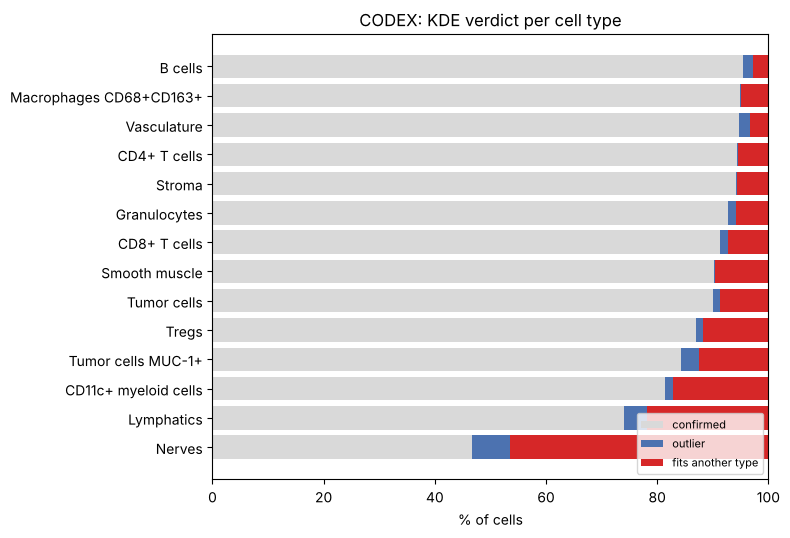

all checked cells: confirmed 91.5%, outlier 1.2%, fits another type 7.3%


,n_cells,confirmed,outlier,fits another type,main competitor
Nerves,2197,46.7,6.9,46.4,CD8+ T cells
Lymphatics,841,74.0,4.3,21.8,Stroma
CD11c+ myeloid cells,4390,81.4,1.4,17.2,Macrophages CD68+CD163+
Tumor cells MUC-1+,10560,84.3,3.3,12.4,Tumor cells
Tregs,9956,86.9,1.4,11.7,CD4+ T cells
Tumor cells,9708,90.0,1.3,8.7,Tumor cells MUC-1+
Smooth muscle,9596,90.2,0.3,9.5,Stroma
CD8+ T cells,17646,91.3,1.5,7.2,CD4+ T cells
Granulocytes,12059,92.8,1.4,5.9,Macrophages CD68+CD163+
Stroma,22894,94.2,0.1,5.7,Smooth muscle


In [17]:
t_cx = flag_table(res_cx, lab_cx)
plot_flag_rates(t_cx, "CODEX: KDE verdict per cell type").savefig(FIG_DIR / "codex_kde_flag_rates.png", dpi=120)
plt.show()
overall = res_cx["flag"].value_counts(normalize=True).reindex(list(FLAG_COLORS)) * 100
print("all checked cells:", ", ".join(f"{k} {v:.1f}%" for k, v in overall.items()))
t_cx.round(1)


**The labels questioned in notebook 02.** After the revision of notebook 02, the CD21-high, CD38-high, CD138+, Granzyme B+ and dim CDX2+
clusters are `unknown` and are not checked here. Two questioned labels remain: **Nerves** (a provisional neural-like profile) and **Tregs**
(possibly activated CD4+ T cells). Does the KDE flag them more than the other types?


In [18]:
suspect = ["Nerves", "Tregs"]
others = t_cx.drop(index=[s for s in suspect if s in t_cx.index])
cmp = t_cx.loc[[s for s in suspect if s in t_cx.index], ["n_cells", "confirmed", "outlier", "fits another type", "main competitor"]]
cmp.loc["(all other types, median)"] = [others["n_cells"].median(), others["confirmed"].median(),
                                        others["outlier"].median(), others["fits another type"].median(), ""]
cmp.round(1)

,n_cells,confirmed,outlier,fits another type,main competitor
Nerves,2197.0,46.7,6.9,46.4,CD8+ T cells
Tregs,9956.0,86.9,1.4,11.7,CD4+ T cells
"(all other types, median)",14694.0,92.0,1.4,6.5,


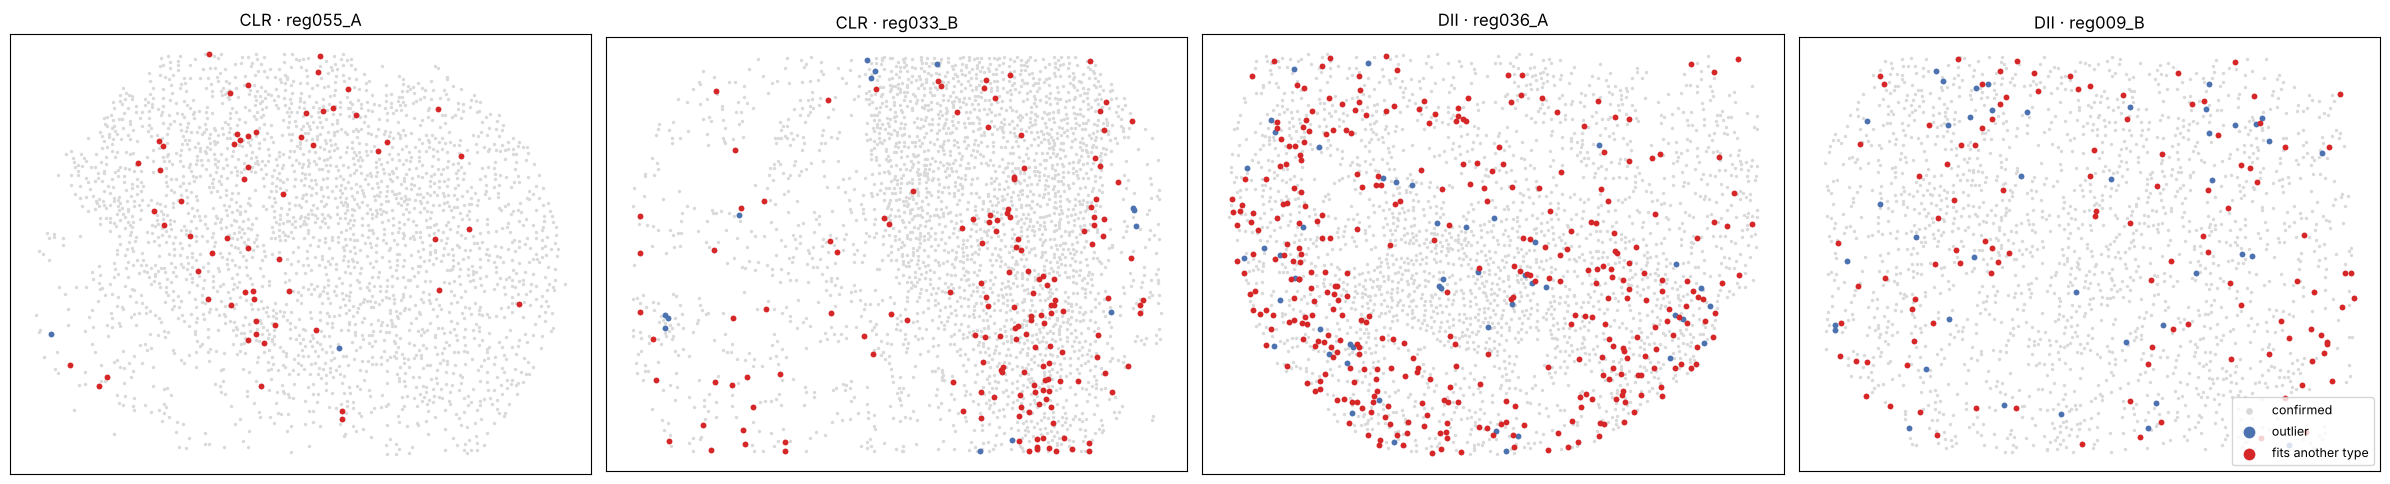

In [19]:
# the same four regions as in notebook 02 (two largest per group)
sizes = cx.obs.groupby(["group", "region"], observed=True).size().rename("n").reset_index()
show = sizes.sort_values("n", ascending=False).groupby("group", observed=True).head(2).sort_values("group")

flag_cx = np.full(cx.n_obs, "not checked", dtype=object)
flag_cx[res_cx.index] = res_cx["flag"].to_numpy()

fig, axes = plt.subplots(1, 4, figsize=(24, 6.5))
for ax, (_, row) in zip(axes, show.iterrows()):
    m = (cx.obs["region"] == row["region"]).to_numpy()
    plot_flag_map(ax, cx.obsm["spatial"][m], flag_cx[m], f"{row['group']} · {row['region']}", s=6)
axes[-1].legend(markerscale=2, loc="lower right", fontsize=9)
plt.tight_layout(); plt.savefig(FIG_DIR / "codex_kde_flag_map.png", dpi=120); plt.show()

,label,competitor,n
0,Tregs,CD4+ T cells,576
1,CD4+ T cells,CD8+ T cells,455
2,Nerves,CD8+ T cells,303


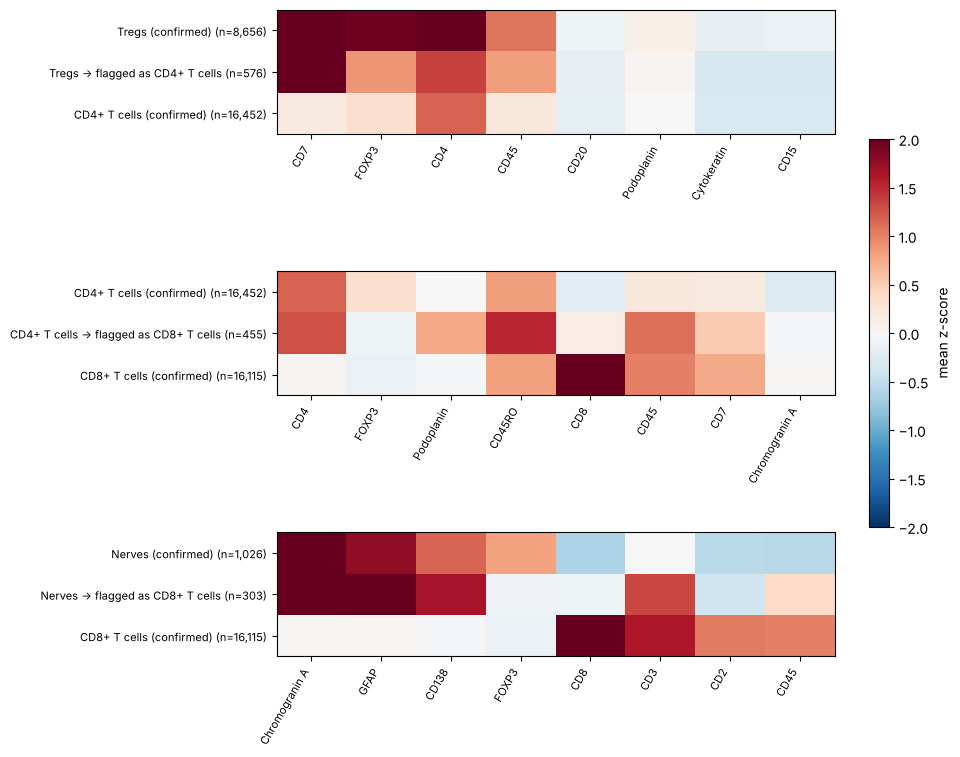

In [20]:
# Two most frequent pairs, plus the two questioned labels that remain after the notebook-02 revision.
pairs_cx = top_pairs(res_cx, lab_cx, n=2)
for label_name in ["Nerves", "Tregs"]:
    mis = res_cx[(res_cx["flag"] == "fits another type") & (lab_cx[res_cx.index] == label_name)]
    if len(mis):
        candidate = pd.DataFrame([{
            "label": label_name,
            "competitor": mis["best_other"].value_counts().index[0],
            "n": int(mis["best_other"].value_counts().iloc[0]),
        }])
        if not ((pairs_cx["label"] == label_name) & (pairs_cx["competitor"] == candidate.iloc[0]["competitor"])).any():
            pairs_cx = pd.concat([pairs_cx, candidate], ignore_index=True)
display(pairs_cx)

if len(pairs_cx):
    lineage = cx.var_names[cx.var["lineage"].to_numpy()] if "lineage" in cx.var else cx.var_names
    X_lin = cx[:, lineage].X
    fig, axes = plt.subplots(len(pairs_cx), 1, figsize=(9, 2.8 * len(pairs_cx)))
    fig.subplots_adjust(hspace=1.1)
    last_im = None
    for ax, (_, pair) in zip(np.atleast_1d(axes), pairs_cx.iterrows()):
        last_im = profile_heatmap(ax, X_lin, lineage, lab_cx, res_cx,
                                  pair["label"], pair["competitor"])
    if last_im is not None:
        plt.colorbar(last_im, ax=np.atleast_1d(axes).tolist(), shrink=0.6, label="mean z-score")
    plt.savefig(FIG_DIR / "codex_kde_flagged_profiles.png", dpi=120, bbox_inches="tight")
    plt.show()
else:
    print("No label→competitor pairs met the minimum cell-count threshold; profile heatmap skipped.")


In [21]:
out = res_cx.copy()
out.insert(0, "cell_id", cx.obs_names[res_cx.index]); out.insert(1, "cell_type", lab_cx[res_cx.index])
out.insert(2, "fold", fold_cx[res_cx.index])
out.to_csv(RESULTS_DIR / "codex_kde.csv", index=False)
print(f"saved {len(out):,} cells to results/codex_kde.csv")

saved 169,948 cells to results/codex_kde.csv


## 5 · Sensitivity

How much do the verdicts depend on the choices? To keep this fast, each variant fits on fold 0 and scores
the same `SENS_N` random cells from fold 1. One setting is changed at a time:

- `K`: 5, 10 (baseline) or 20 PCs.
- **Bandwidth:** the held-out choice (baseline), or fixed at 0.5×, 1× or 2× Scott.
- `N`: 500, 1000 (baseline) or 2000 support cells per type.
- `Q`: 0.5%, 1% (baseline) or 5%. This needs no refit.
- **Priors:** type frequencies (baseline) or uniform. Frequency priors make rare types (mast cells, pDCs) harder to confirm.

Each variant reports the overall verdict rates and the **agreement**, the fraction of cells whose verdict matches the baseline.

In [22]:
def sensitivity(X_all, labels, fold, types, seed=SEED):
    """Compare parameter choices on the same held-out fold-1 cells."""
    X_all = np.asarray(X_all, dtype=float)
    labels = np.asarray(labels).astype(str)
    fold = np.asarray(fold)
    r = np.random.default_rng(seed)
    test_pool = np.flatnonzero((fold == 1) & np.isin(labels, types))
    if len(test_pool) == 0:
        raise ValueError("No labeled cells in fold 1 for sensitivity analysis.")
    n_test = min(SENS_N, len(test_pool))
    if n_test < SENS_N:
        print(f"Note: scoring {n_test:,} cells rather than SENS_N={SENS_N:,}; fewer eligible fold-1 cells are available.")
    test = r.choice(test_pool, n_test, replace=False)
    fit = fold == 0

    variants = [("baseline", {}), ("K = 5", {"k": 5})]
    if X_all.shape[1] >= 20:
        variants.append(("K = 20", {"k": 20}))
    else:
        print(f"Skipping K = 20 sensitivity: only {X_all.shape[1]} PCs are available.")
    variants += [
        ("bandwidth 0.5x Scott", {"h": [0.5]}),
        ("bandwidth 1x Scott", {"h": [1.0]}),
        ("bandwidth 2x Scott", {"h": [2.0]}),
        ("N = 500", {"n": 500}),
        ("N = 2000", {"n": 2000}),
        ("Q = 0.5%", {"q": 0.5}),
        ("Q = 5%", {"q": 5.0}),
        ("uniform priors", {"uniform": True}),
    ]
    rows, base, cache = [], None, {}
    for name, variant in variants:
        k = variant.get("k", K)
        h = variant.get("h", H_GRID)
        n = variant.get("n", N)
        q = variant.get("q", Q)
        key = (k, tuple(h), n)
        if key not in cache:
            Xk = X_all[:, :k]
            models = fit_type_kdes(Xk[fit], labels[fit], types, n_support=n,
                                   h_grid=h, seed=seed)
            cache[key] = (models, log_lik(Xk[test], models))
        models, LL = cache[key]
        flags = verdicts(LL, labels[test], models, q=q,
                         uniform_prior=variant.get("uniform", False))["flag"].to_numpy()
        if base is None:
            base = flags
        rates = pd.Series(flags).value_counts(normalize=True).reindex(list(FLAG_COLORS), fill_value=0) * 100
        rows.append({
            "variant": name, **rates.round(1).to_dict(),
            "agreement with baseline %": round((flags == base).mean() * 100, 1)
        })
    return pd.DataFrame(rows).set_index("variant")


In [23]:
sens_xe = sensitivity(xe.obsm["X_pca"], lab_xe, fold_xe, types_xe)
sens_xe

,confirmed,outlier,fits another type,agreement with baseline %
variant,,,,
baseline,94.8,0.4,4.9,100.0
K = 5,94.6,0.4,5.0,93.2
K = 20,94.3,0.4,5.3,93.5
bandwidth 0.5x Scott,79.4,0.1,20.6,83.1
bandwidth 1x Scott,94.8,0.4,4.9,100.0
bandwidth 2x Scott,95.7,1.1,3.3,94.3
N = 500,94.4,0.3,5.3,96.7
N = 2000,95.0,0.4,4.6,97.6
Q = 0.5%,94.9,0.2,4.9,99.8


In [24]:
sens_cx = sensitivity(cx.obsm["X_pca"], lab_cx, fold_cx, types_cx)
sens_cx

,confirmed,outlier,fits another type,agreement with baseline %
variant,,,,
baseline,91.2,1.0,7.7,100.0
K = 5,91.9,0.7,7.4,90.6
K = 20,87.0,0.9,12.1,87.8
bandwidth 0.5x Scott,77.2,0.3,22.5,82.4
bandwidth 1x Scott,91.5,1.0,7.4,99.7
bandwidth 2x Scott,92.4,1.6,6.0,91.2
N = 500,91.0,1.0,8.1,96.5
N = 2000,91.7,1.3,7.0,96.5
Q = 0.5%,91.5,0.6,7.9,99.5


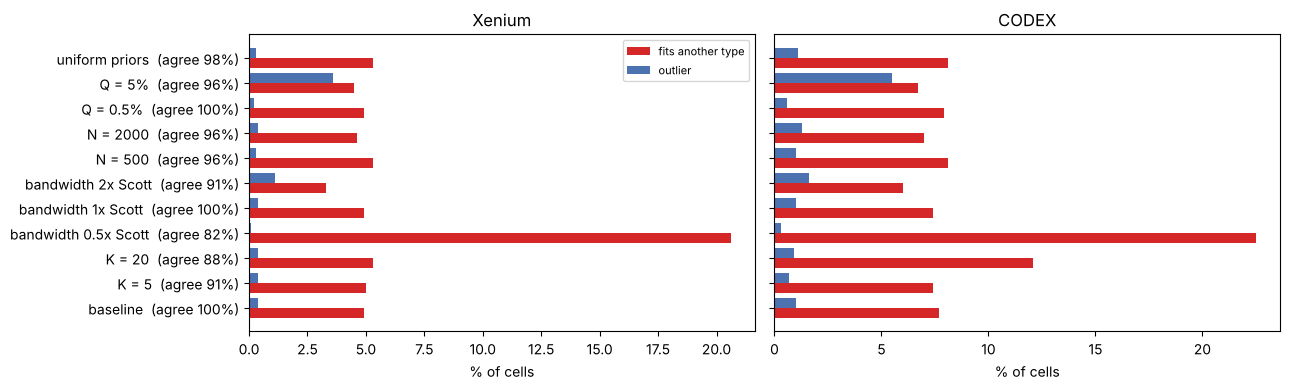

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (name, s) in zip(axes, [("Xenium", sens_xe), ("CODEX", sens_cx)]):
    y = np.arange(len(s))
    ax.barh(y - 0.2, s["fits another type"], 0.4, color=FLAG_COLORS["fits another type"], label="fits another type")
    ax.barh(y + 0.2, s["outlier"], 0.4, color=FLAG_COLORS["outlier"], label="outlier")
    ax.set_yticks(y, [f"{v}  (agree {a:.0f}%)" for v, a in zip(s.index, s["agreement with baseline %"])])
    ax.invert_yaxis(); ax.set(xlabel="% of cells", title=name)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "kde_sensitivity.png", dpi=120); plt.show()

## 5b · Robustness across random folds and support samples

The baseline uses one fold assignment and one random support sample per type. Here the whole cross-fitting is repeated with `N_SEEDS` different seeds,
each with a **new fold assignment** (new tiles to folds for Xenium, new patient split for CODEX) and **new support samples**. To keep it fast, every
repeat scores the same fixed evaluation set: up to `EVAL_PER_TYPE` random cells per type. Reported per type: the mean flag rate, its range across
seeds, and the share of evaluation cells whose verdict is identical in every repeat.

In [26]:
N_SEEDS, EVAL_PER_TYPE = 5, 600

def folds_xenium(seed):
    r = np.random.default_rng(seed)
    f = dict(zip(tiles, r.permutation(np.arange(len(tiles)) % 2)))
    return np.array([f[t] for t in tile])

def folds_codex(seed):
    r = np.random.default_rng(seed); f = {}
    for g, pats in pat_group.groupby(pat_group):
        perm = r.permutation(pats.index.to_numpy()); f.update({p: i % 2 for i, p in enumerate(perm)})
    return cx.obs["patient"].map(f).astype(int).to_numpy()

def repeat_verdicts(X, labels, types, fold_fn):
    r = np.random.default_rng(SEED)
    eval_idx = np.concatenate([r.choice(np.flatnonzero(labels == c), min(EVAL_PER_TYPE, (labels == c).sum()), replace=False)
                               for c in types])
    out = pd.DataFrame(index=eval_idx)
    for s in range(1, N_SEEDS + 1):
        fold = fold_fn(s); col = pd.Series(index=eval_idx, dtype=object)
        for f in (0, 1):
            fit = fold == f
            score = eval_idx[fold[eval_idx] != f]
            m = fit_type_kdes(X[fit], labels[fit], types, seed=SEED + 100 * s + f)
            col.loc[score] = verdicts(log_lik(X[score], m), labels[score], m)["flag"].to_numpy()
        out[f"seed {s}"] = col
    lab = labels[eval_idx]
    flagged = out.ne("confirmed")
    per_seed = flagged.groupby(lab).mean() * 100
    table = pd.DataFrame({"eval cells": pd.Series(lab).value_counts(),
                          "flag rate mean %": per_seed.mean(1), "min %": per_seed.min(1), "max %": per_seed.max(1),
                          "same verdict in all seeds %": (out.nunique(axis=1) == 1).groupby(lab).mean() * 100}).round(1)
    return table.sort_values("flag rate mean %", ascending=False), (out.nunique(axis=1) == 1).mean() * 100

rob_xe, stable_xe = repeat_verdicts(X_xe, lab_xe, types_xe, folds_xenium)
print(f"Xenium: verdict identical in all {N_SEEDS} repeats for {stable_xe:.1f}% of evaluation cells")
rob_xe

/tmp/ipykernel_359/1217601418.py:31: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  "flag rate mean %": per_seed.mean(1), "min %": per_seed.min(1), "max %": per_seed.max(1),
/tmp/ipykernel_359/1217601418.py:31: Pandas4Warning: Starting with pandas version 4.0 all arguments of min will be keyword-only.
  "flag rate mean %": per_seed.mean(1), "min %": per_seed.min(1), "max %": per_seed.max(1),
/tmp/ipykernel_359/1217601418.py:31: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  "flag rate mean %": per_seed.mean(1), "min %": per_seed.min(1), "max %": per_seed.max(1),


Xenium: verdict identical in all 5 repeats for 86.2% of evaluation cells


,eval cells,flag rate mean %,min %,max %,same verdict in all seeds %
Mast cells,600,33.1,31.7,34.7,77.5
Adipocytes,600,29.1,24.0,40.7,62.0
NK cells,600,24.1,22.7,26.5,72.0
Mature DCs,600,23.5,22.3,24.8,69.2
pDCs,600,16.4,15.3,16.8,82.3
CAF / myofibroblasts,600,10.1,9.7,11.3,82.8
Proliferating invasive tumor,600,9.2,8.0,10.3,81.5
Macrophages APOC1+,600,8.6,8.0,9.3,84.2
DCIS 1,600,8.3,7.5,9.3,87.3
DCIS 2,600,6.0,4.5,7.3,90.2


In [27]:
rob_cx, stable_cx = repeat_verdicts(X_cx, lab_cx, types_cx, folds_codex)
print(f"CODEX: verdict identical in all {N_SEEDS} repeats for {stable_cx:.1f}% of evaluation cells")
rob_cx

/tmp/ipykernel_359/1217601418.py:31: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  "flag rate mean %": per_seed.mean(1), "min %": per_seed.min(1), "max %": per_seed.max(1),
/tmp/ipykernel_359/1217601418.py:31: Pandas4Warning: Starting with pandas version 4.0 all arguments of min will be keyword-only.
  "flag rate mean %": per_seed.mean(1), "min %": per_seed.min(1), "max %": per_seed.max(1),
/tmp/ipykernel_359/1217601418.py:31: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  "flag rate mean %": per_seed.mean(1), "min %": per_seed.min(1), "max %": per_seed.max(1),


CODEX: verdict identical in all 5 repeats for 79.4% of evaluation cells


,eval cells,flag rate mean %,min %,max %,same verdict in all seeds %
Nerves,600,35.2,30.5,42.2,42.2
Lymphatics,600,24.2,22.0,27.5,65.2
CD11c+ myeloid cells,600,19.3,18.2,20.3,74.8
Tumor cells MUC-1+,600,16.8,12.3,21.3,71.3
Tregs,600,11.6,9.8,14.3,75.0
CD8+ T cells,600,9.3,8.3,10.7,83.2
Smooth muscle,600,8.5,7.7,9.2,85.2
CD4+ T cells,600,7.9,7.3,8.2,82.2
Tumor cells,600,7.0,6.5,7.5,87.3
Granulocytes,600,6.6,5.7,7.3,85.3


**Result.**
- **Overall:** across 5 repeats, 86% (Xenium) and 79% (CODEX) of evaluation cells get the same verdict every time.
- **Stable types:** for most types the flag rate moves by only a few percentage points.
- **Unstable types:** adipocytes (24–41%), Nerves (31–42%) and MUC-1+ tumor cells (12–21%). For Nerves only 42% of cells keep the same verdict in every repeat.

Single-run flags for these types should not be over-read.

**Rare types.** A high flag rate for a small type has several possible causes: a heterogeneous class, a few key markers that weigh little in the first `K` PCs,
too few support cells for a stable density, overlap with a related type, or a wrong label. The KDE cannot tell these apart. The range across seeds shows
how stable each rate is; the marker heatmaps above, not the flag rate alone, are the evidence for or against a label.

### Xenium tile edges

Do cells close to a fold boundary look more typical, because near-copies in the other fold help build their type's density? Cells within
`EDGE_UM` µm of a tile edge are compared with cells farther inside their tile, using the baseline verdicts.

In [28]:
EDGE_UM = 30
xy_ok = xy[res_xe.index]
dist = np.minimum.reduce([xy_ok[:, 0] % TILE_UM, TILE_UM - xy_ok[:, 0] % TILE_UM,
                          xy_ok[:, 1] % TILE_UM, TILE_UM - xy_ok[:, 1] % TILE_UM])
near = dist < EDGE_UM
edge_tab = pd.crosstab(np.where(near, f"within {EDGE_UM} µm of a tile edge", "farther inside"),
                       res_xe["flag"].to_numpy(), normalize="index").reindex(columns=list(FLAG_COLORS)) * 100
edge_tab.insert(0, "cells", pd.Series(np.where(near, f"within {EDGE_UM} µm of a tile edge", "farther inside")).value_counts())
edge_tab.rename_axis(index=None, columns=None).round(2)

,cells,confirmed,outlier,fits another type
farther inside,124290,94.63,0.43,4.94
within 30 µm of a tile edge,35540,94.41,0.43,5.15


**Result.** Cells within 30 µm of a tile edge are flagged 5.6% of the time, against 5.4% farther inside. There is no sign that near-copies in the other fold
make edge cells look more typical, so the tile blocking is adequate for this check.

In [29]:
# Summary of this run (computed, not copied): overall verdicts, most-flagged types, sensitivity range
def run_summary(name, res, t, sens):
    rates = res["flag"].value_counts(normalize=True).reindex(list(FLAG_COLORS), fill_value=0) * 100
    print(f"{name}: " + ", ".join(f"{k} {v:.1f}%" for k, v in rates.items()))
    top = t.sort_values("fits another type", ascending=False).head(5)
    for typ, row in top.iterrows():
        print(f"   {typ:30s} {row['fits another type']:5.1f}% fits another type  (main competitor: {row['main competitor']})")
    agree = sens.drop(index="baseline")["agreement with baseline %"]
    print(f"   sensitivity: agreement with baseline {agree.min():.0f}–{agree.max():.0f}% (lowest: {agree.idxmin()})")

run_summary("Xenium", res_xe, t_xe, sens_xe)
run_summary("CODEX", res_cx, t_cx, sens_cx)
print(f"robustness over {N_SEEDS} fold/support repeats: identical verdict for {stable_xe:.1f}% (Xenium) and {stable_cx:.1f}% (CODEX) of evaluation cells")
print("Xenium tile-edge check (% flagged):", (100 - edge_tab["confirmed"]).round(2).to_dict())


Xenium: confirmed 94.6%, outlier 0.4%, fits another type 5.0%
   Mast cells                      33.9% fits another type  (main competitor: Fibroblasts)
   Adipocytes                      27.1% fits another type  (main competitor: Fibroblasts)
   Mature DCs                      23.7% fits another type  (main competitor: CD4+ T cells)
   NK cells                        22.4% fits another type  (main competitor: CD8+ T cells)
   pDCs                            17.4% fits another type  (main competitor: Macrophages CD163+)
   sensitivity: agreement with baseline 83–100% (lowest: bandwidth 0.5x Scott)
CODEX: confirmed 91.5%, outlier 1.2%, fits another type 7.3%
   Nerves                          46.4% fits another type  (main competitor: CD8+ T cells)
   Lymphatics                      21.8% fits another type  (main competitor: Stroma)
   CD11c+ myeloid cells            17.2% fits another type  (main competitor: Macrophages CD68+CD163+)
   Tumor cells MUC-1+              12.4% fits another

## 6 · Interpretation and reporting

The summary above is computed from this run. Re-run the notebook from the beginning after any upstream change (labels, PCA, parameters) to regenerate it.

Use the generated tables to answer these questions:

- **Overall calibration:** Is the observed outlier rate near the chosen `Q = 1%` threshold? A different rate is possible because the threshold is calibrated on held-out cells within the fitting fold and then applied to cells in the other fold.
- **Type-specific patterns:** Which labels have elevated `fits another type` rates, and which competing types are most common? Small cell types and types weakly represented in the first `K` PCs need particular caution.
- **Spatial distribution:** Are flags concentrated in particular tissue areas, regions, or patient samples? Spatial clustering of flags can indicate technical artifacts, biological transitions, or a limitation of the feature space; it does not establish which explanation is correct.
- **Profile heatmaps:** Do flagged cells resemble the proposed competing type, fall between the two profiles, or show neither pattern? Interpret this alongside marker evidence from notebooks 01–02.
- **Sensitivity:** If the verdict changes substantially with `K`, bandwidth, support size `N`, threshold `Q`, or priors, report the annotation as uncertain rather than relying on a single parameter setting.

**Validation hierarchy.** Marker coherence (notebooks 01–02), spatial consistency (01–02), KDE consistency (this notebook), agreement with the published labels and patient-level replication (04) are complementary kinds of evidence, not interchangeable tests. None of them alone establishes identity.

**Limitations.** The KDE checks consistency in the selected PCA space; it cannot independently establish cell identity, resolve a biologically ambiguous label, or prove doublets/spillover. The held-out likelihood and threshold are internal diagnostics, not external validation. CODEX spatial and patient-level patterns should be interpreted with the patient as the biological unit.

**Next.** Notebook 04 can compare the flagged cells with the authors' labels. That comparison is a separate validation source; the authors' labels are not used to fit the KDEs here.
